# Predicting ChlorA (Chlorophyll-a) — CalCOFI

**Goal:** Build a regression model to predict `ChlorA` (µg/L chlorophyll-a) from bottle + cast oceanographic features.

This notebook starts with data loading, field descriptions, joining on `Cst_Cnt`, and exploratory analysis.

## 1. Imports & load data

In [2]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_colwidth", 120)

DATA_DIR = "../data"
OUT_DIR = Path("model_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42

In [5]:
# Bottle = per-depth water samples; Cast = per-station cast metadata
bottle = pd.read_csv(f"{DATA_DIR}/bottle.csv", encoding="iso-8859-1", low_memory=False)
cast = pd.read_csv(f"{DATA_DIR}/cast.csv", encoding="iso-8859-1", low_memory=False)

print(f"bottle shape: {bottle.shape}")
print(f"cast shape:   {cast.shape}")
display(bottle.head(3))
display(cast.head(3))

bottle shape: (895371, 62)
cast shape:   (35644, 61)


,Cst_Cnt,Btl_Cnt,Sta_ID,Depth_ID,Depthm,T_degC,Salnty,O2ml_L,STheta,O2Sat,Oxy_µmol/Kg,BtlNum,RecInd,T_prec,T_qual,S_prec,S_qual,P_qual,O_qual,SThtaq,O2Satq,ChlorA,Chlqua,Phaeop,Phaqua,PO4uM,PO4q,SiO3uM,SiO3qu,NO2uM,NO2q,NO3uM,NO3q,NH3uM,NH3q,C14As1,C14A1p,C14A1q,C14As2,C14A2p,C14A2q,DarkAs,DarkAp,DarkAq,MeanAs,MeanAp,MeanAq,IncTim,LightP,R_Depth,R_TEMP,R_Sal,R_DYNHT,R_Nuts,R_Oxy_µmol/Kg,DIC1,DIC2,TA1,TA2,pH1,pH2,DIC Quality Comment
0,1,1,054.0 056.0,19-4903CR-HY-060-0930-05400560-0000A-3,0,10.50,33.440,NaN,25.649,NaN,NaN,NaN,3,1.0,NaN,2.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,0.0,10.50,233.0,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2,054.0 056.0,19-4903CR-HY-060-0930-05400560-0008A-3,8,10.46,33.440,NaN,25.656,NaN,NaN,NaN,3,2.0,NaN,2.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,8.0,10.46,232.5,0.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,3,054.0 056.0,19-4903CR-HY-060-0930-05400560-0010A-7,10,10.46,33.437,NaN,25.654,NaN,NaN,NaN,7,2.0,NaN,3.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,10.0,10.46,232.8,0.02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Cst_Cnt,Cruise_ID,Cruise,Cruz_Sta,DbSta_ID,Cast_ID,Sta_ID,Quarter,Sta_Code,Distance,Date,Year,Month,Julian_Date,Julian_Day,Time,Lat_Dec,Lat_Deg,Lat_Min,Lat_Hem,Lon_Dec,Lon_Deg,Lon_Min,Lon_Hem,Rpt_Line,St_Line,Ac_Line,Rpt_Sta,St_Station,Ac_Sta,Bottom_D,Secchi,ForelU,Ship_Name,Ship_Code,Data_Type,Order_Occ,Event_Num,Cruz_Leg,Orig_Sta_ID,Data_Or,Cruz_Num,IntChl,IntC14,Inc_Str,Inc_End,PST_LAN,Civil_T,TimeZone,Wave_Dir,Wave_Ht,Wave_Prd,Wind_Dir,Wind_Spd,Barometer,Dry_T,Wet_T,Wea,Cloud_Typ,Cloud_Amt,Visibility
0,1,1949-03-01-C-31CR,194903,19490305400560,5400560,19-4903CR-HY-060-0930-05400560,054.0 056.0,1,NST,NaN,03/01/1949,1949,3,17958,60,09:30:00,38.833333,38,50.0,N,-124.083333,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
1,2,1949-03-01-C-31CR,194903,19490305200750,5200750,19-4903CR-HY-060-2112-05200750,052.0 075.0,1,NST,NaN,03/01/1949,1949,3,17958,60,21:12:00,38.583333,38,35.0,N,-125.800000,-125,48.0,W,52.0,52.0,51.5,75.0,75.0,75.1,NaN,NaN,NaN,CREST,31CR,HY,NaN,2.0,NaN,052 75,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16.0,5.0,NaN,NaN,NaN,4.0,NaN,NaN,NaN
2,3,1949-03-01-C-31CR,194903,19490305100850,5100850,19-4903CR-HY-061-0354-05100850,051.0 085.0,1,NST,NaN,03/02/1949,1949,3,17959,61,03:54:00,38.475000,38,28.5,N,-126.666666,-126,40.0,W,51.0,51.0,50.3,85.0,85.0,84.7,NaN,NaN,NaN,CREST,31CR,HY,NaN,3.0,NaN,051 85,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,5.0,NaN,NaN,NaN,6.0,NaN,NaN,NaN


## 2. Field descriptions

Lookup tables describing each column in the bottle and cast tables.

In [6]:
bottle_desc = pd.read_csv(f"{DATA_DIR}/Bottle Field Descriptions.csv", encoding="iso-8859-1")
cast_desc = pd.read_csv(f"{DATA_DIR}/Cast Field Descriptions.csv", encoding="iso-8859-1")

# Drop empty trailing columns if present
bottle_desc = bottle_desc.dropna(axis=1, how="all")
cast_desc = cast_desc.dropna(axis=1, how="all")

print("=== Bottle field descriptions ===")
display(bottle_desc)

print("=== Cast field descriptions ===")
display(cast_desc)

=== Bottle field descriptions ===


,Field Name,Units,Description
0,Cst_Cnt,n.a.,"Cast Count - All CalCOFI casts ever conducted, consecutively numbered"
1,Btl_Cnt,n.a.,"Bottle Count - All CalCOFI bottles ever sampled, consecutively numbered"
2,Sta_ID,n.a.,Line and Station [Line] [Station]
3,Depth_ID,n.a.,Uses the Cast_ID prefix ([Century]-[Year][Month][ShipCode]-[CastType][Julian Day]-[CastTime]-[Line][Sta]) but adds t...
4,Depthm,meters,Bottle depth in meters
...,...,...,...
57,TA1,micromoles per kilogram,Total Alkalinity micromoles per kilogram solution
58,TA2,micromoles per kilogram,Total Alkalinity micromoles per kilogram solution (on a replicate sample)
59,pH1,pH scale,pH (the degree of acidity/alkalinity of a solution)
60,pH2,pH scale,pH (the degree of acidity/alkalinity of a solution) on a replicate sample


=== Cast field descriptions ===


,Field Name,Units,Description
0,Cst_Cnt,n.a.,"Cast Count - All CalCOFI casts ever conducted, consecutively numbered"
1,Cruise_ID,n.a.,Cruise identifier [Year]-[Month]-[Day]-C-[Ship Code]
2,Cruise,n.a.,Cruise Name [Year][Month]
3,Cruz_Sta,n.a.,Cruise Name and Station [Year][Month][Line][Station]
4,DbSta_ID,n.a.,Line and Station
...,...,...,...
56,Cloud_Typ,n.a.,"1 Digit Code from The World Meteorlogical Organization, Code source WMO 0500"
57,Cloud_Amt,n.a.,"1 Digit Code from The World Meteorlogical Organization, Code source WMO 2700, in oktas"
58,Visibility,n.a.,"1 Digit Code from The World Meteorlogical Organization, Code source WMO 4300"
59,Secchi,meters,Secchi disk depth in meters


In [23]:
def whatis(field_name, fd):
        print(fd[fd['Field Name']==field_name]['Description'])

In [24]:
whatis('ChlorA',bottle_desc)

21    Migrograms Chlorophyll-a per liter seawater, measured fluorometrically
Name: Description, dtype: object


## 3. Join bottle cast on `Cst_Cnt`

Each cast can have many bottles (depths). We left-join cast metadata onto every bottle row.

In [25]:
# Drop overlapping columns from cast (except join key) so we don't create _x/_y suffixes
overlap = [c for c in cast.columns if c in bottle.columns and c != "Cst_Cnt"]
print("Overlapping columns (kept from bottle, cast versions dropped):", overlap)

cast_for_join = cast.drop(columns=overlap)
df = bottle.merge(cast_for_join, on="Cst_Cnt", how="left")

print(f"\nJoined shape: {df.shape}")
print(f"Rows with ChlorA present: {df['ChlorA'].notna().sum():,} / {len(df):,}")
df.head(3)


Overlapping columns (kept from bottle, cast versions dropped): ['Sta_ID']

Joined shape: (895371, 121)
Rows with ChlorA present: 245,666 / 895,371


,Cst_Cnt,Btl_Cnt,Sta_ID,Depth_ID,Depthm,T_degC,Salnty,O2ml_L,STheta,O2Sat,Oxy_µmol/Kg,BtlNum,RecInd,T_prec,T_qual,S_prec,S_qual,P_qual,O_qual,SThtaq,O2Satq,ChlorA,Chlqua,Phaeop,Phaqua,PO4uM,PO4q,SiO3uM,SiO3qu,NO2uM,NO2q,NO3uM,NO3q,NH3uM,NH3q,C14As1,C14A1p,C14A1q,C14As2,C14A2p,...,Lon_Deg,Lon_Min,Lon_Hem,Rpt_Line,St_Line,Ac_Line,Rpt_Sta,St_Station,Ac_Sta,Bottom_D,Secchi,ForelU,Ship_Name,Ship_Code,Data_Type,Order_Occ,Event_Num,Cruz_Leg,Orig_Sta_ID,Data_Or,Cruz_Num,IntChl,IntC14,Inc_Str,Inc_End,PST_LAN,Civil_T,TimeZone,Wave_Dir,Wave_Ht,Wave_Prd,Wind_Dir,Wind_Spd,Barometer,Dry_T,Wet_T,Wea,Cloud_Typ,Cloud_Amt,Visibility
0,1,1,054.0 056.0,19-4903CR-HY-060-0930-05400560-0000A-3,0,10.50,33.440,NaN,25.649,NaN,NaN,NaN,3,1.0,NaN,2.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
1,1,2,054.0 056.0,19-4903CR-HY-060-0930-05400560-0008A-3,8,10.46,33.440,NaN,25.656,NaN,NaN,NaN,3,2.0,NaN,2.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
2,1,3,054.0 056.0,19-4903CR-HY-060-0930-05400560-0010A-7,10,10.46,33.437,NaN,25.654,NaN,NaN,NaN,7,2.0,NaN,3.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN


## 4. Exploratory Data Analysis

We work with rows that have a measured `ChlorA` value. Quality-code / precision columns (`*q`, `*_qual`, `*_prec`) are dropped from the correlation view so the heatmap stays readable.

In [26]:
# ChlorA-present subset for EDA plots
eda = df[df["ChlorA"].notna()].copy()
print(f"EDA subset (ChlorA not null): {eda.shape}")

EDA subset (ChlorA not null): (245666, 121)


### 4.1 Correlation heatmap (numerical features)

In [27]:
whatis('DIC1',bottle_desc)

55    Dissolved Inorganic Carbon micromoles per kilogram solution
Name: Description, dtype: object


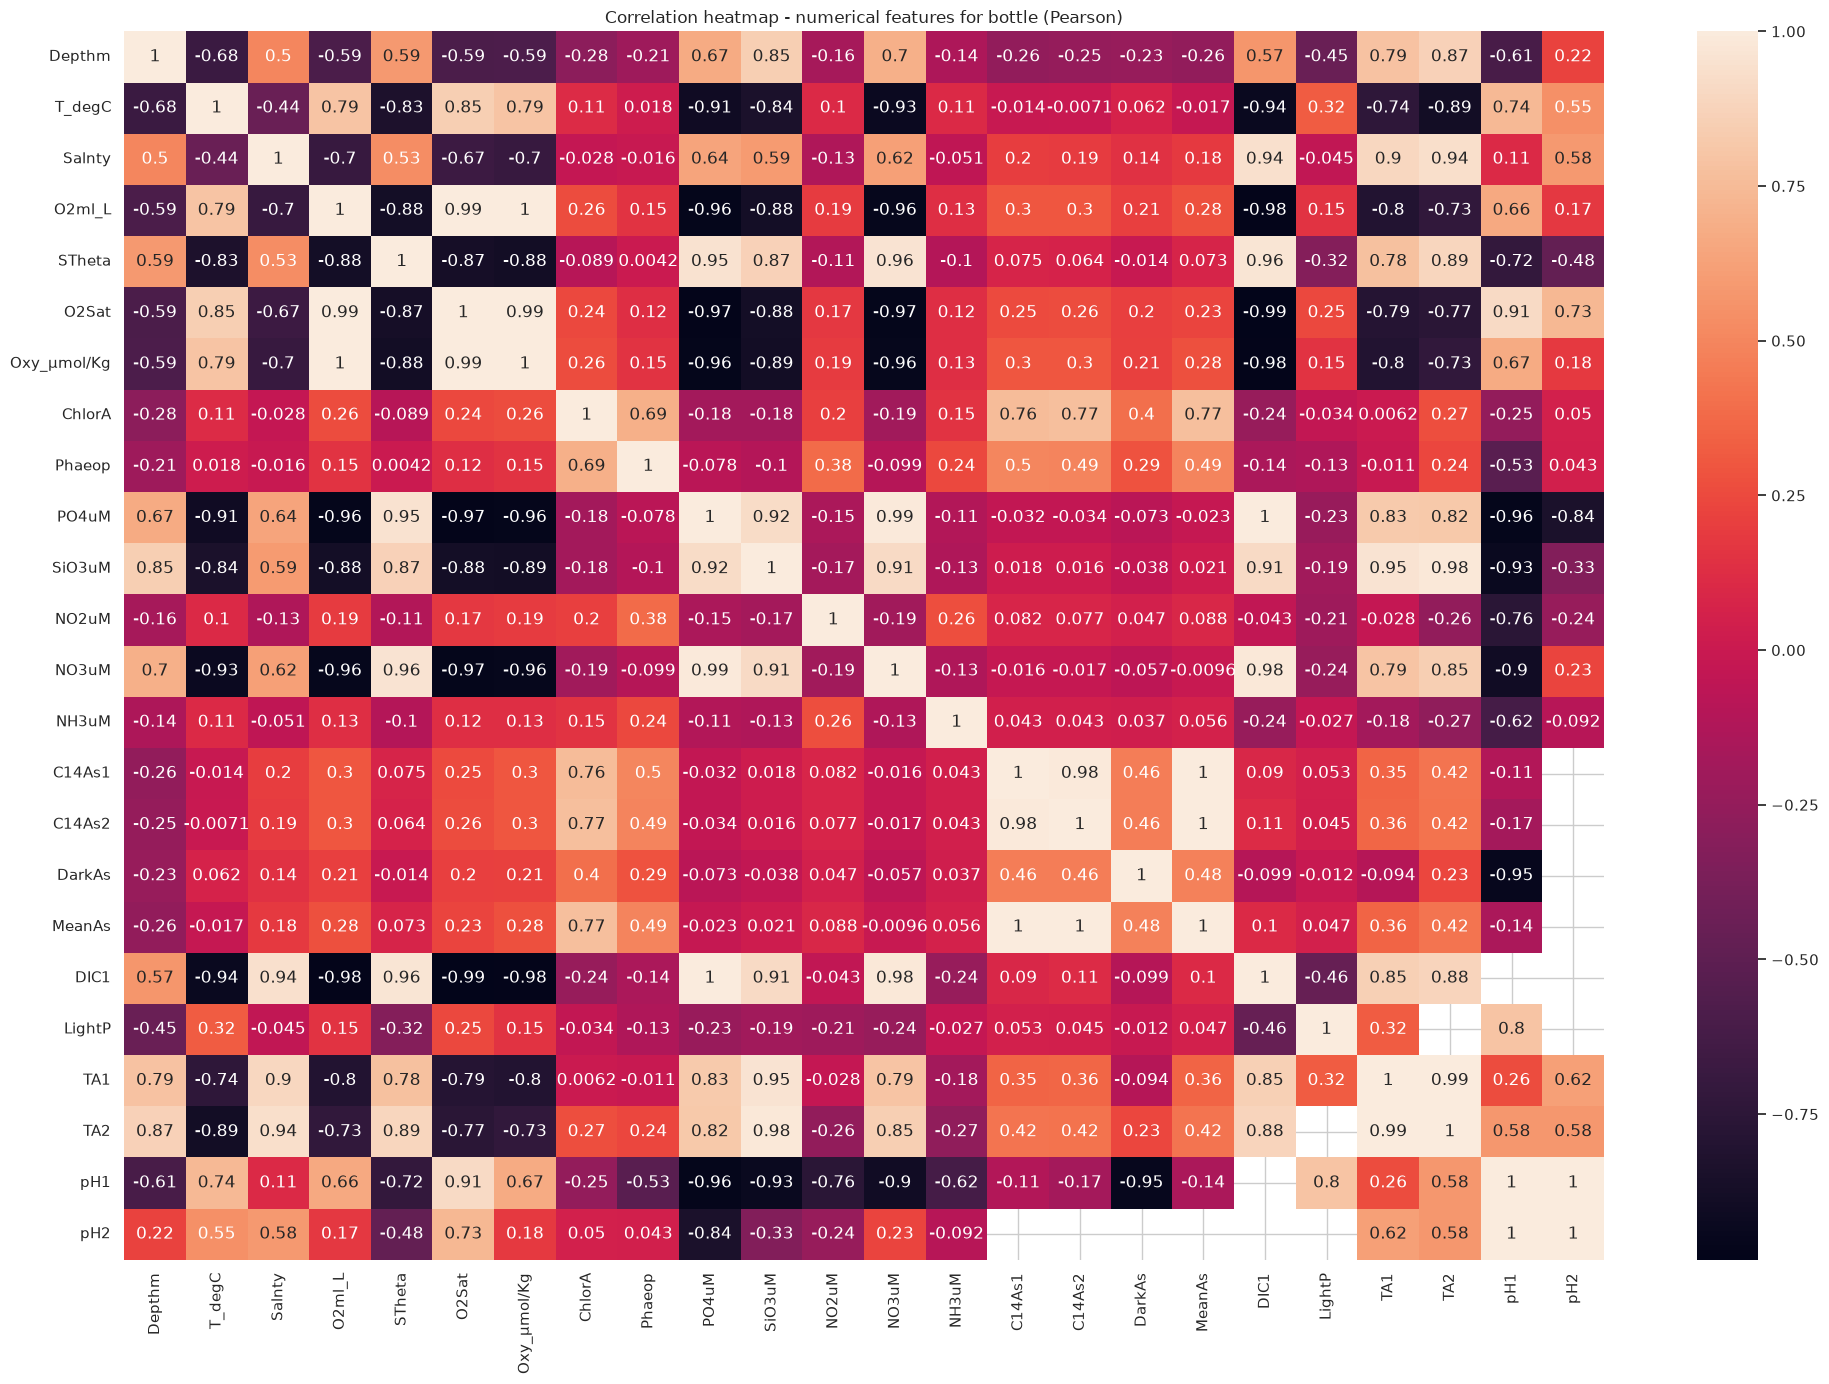

Top |correlations| with ChlorA:


,corr_with_ChlorA
C14As2,0.773470
MeanAs,0.769239
C14As1,0.755759
Phaeop,0.690607
DarkAs,0.401677
Depthm,-0.284359
TA2,0.265072
Oxy_µmol/Kg,0.260504
O2ml_L,0.257735
pH1,-0.252642


In [28]:
# Resolve oxygen column (mu character varies by file encoding)
_oxy = next((c for c in df.columns if c.startswith("Oxy_") and "mol/Kg" in c and not c.startswith("R_")), None)

bottle_numeric_features = [
    "Depthm", "T_degC", "Salnty", "O2ml_L", "STheta", "O2Sat",
    _oxy, "ChlorA", "Phaeop", "PO4uM", "SiO3uM", "NO2uM", "NO3uM", "NH3uM",
    "C14As1", "C14As2", "DarkAs", "MeanAs", "DIC1",
    "LightP", "TA1", "TA2", "pH1", "pH2",
]
bottle_numeric_features = [c for c in bottle_numeric_features if c is not None and c in df.columns]

corr = df[bottle_numeric_features].corr(method="pearson", numeric_only=True)

fig, ax = plt.subplots(figsize=(20, 14))
sns.heatmap(corr, annot=True, ax=ax)
ax.set_title("Correlation heatmap - numerical features for bottle (Pearson)")
plt.tight_layout()
plt.show()

# ChlorA correlations ranked
if "ChlorA" in corr.columns:
    chlora_corr = corr["ChlorA"].drop("ChlorA").sort_values(key=abs, ascending=False)
    print("Top |correlations| with ChlorA:")
    display(chlora_corr.head(15).to_frame("corr_with_ChlorA"))

In [31]:
whatis('C14As2',bottle_desc)

38    14C Assimilation of Replicate 2 (milligrams carbon per cubic meter of seawater per half light day)
Name: Description, dtype: object


In [32]:
whatis('MeanAs',bottle_desc)

44    Mean 14C Assimilation of Replicates 1 and 2 (milligrams carbon per cubic meter of seawater per half light day)
Name: Description, dtype: object


In [33]:
whatis('Phaeop',bottle_desc)

23    Micrograms Phaeopigment per liter seawater, measured fluormetrically
Name: Description, dtype: object


In [34]:
whatis('DarkAs',bottle_desc)

41    14C Assimilation of Dark/Control Bottle (milligrams carbon per cubic meter of seawater per half light day)
Name: Description, dtype: object


In [35]:
whatis('TA2',bottle_desc)

58    Total Alkalinity micromoles per kilogram solution (on a replicate sample)
Name: Description, dtype: object


C14As2 : 14C Assimilation of Replicate 2 (milligrams carbon per cubic meter of seawater per half light day)

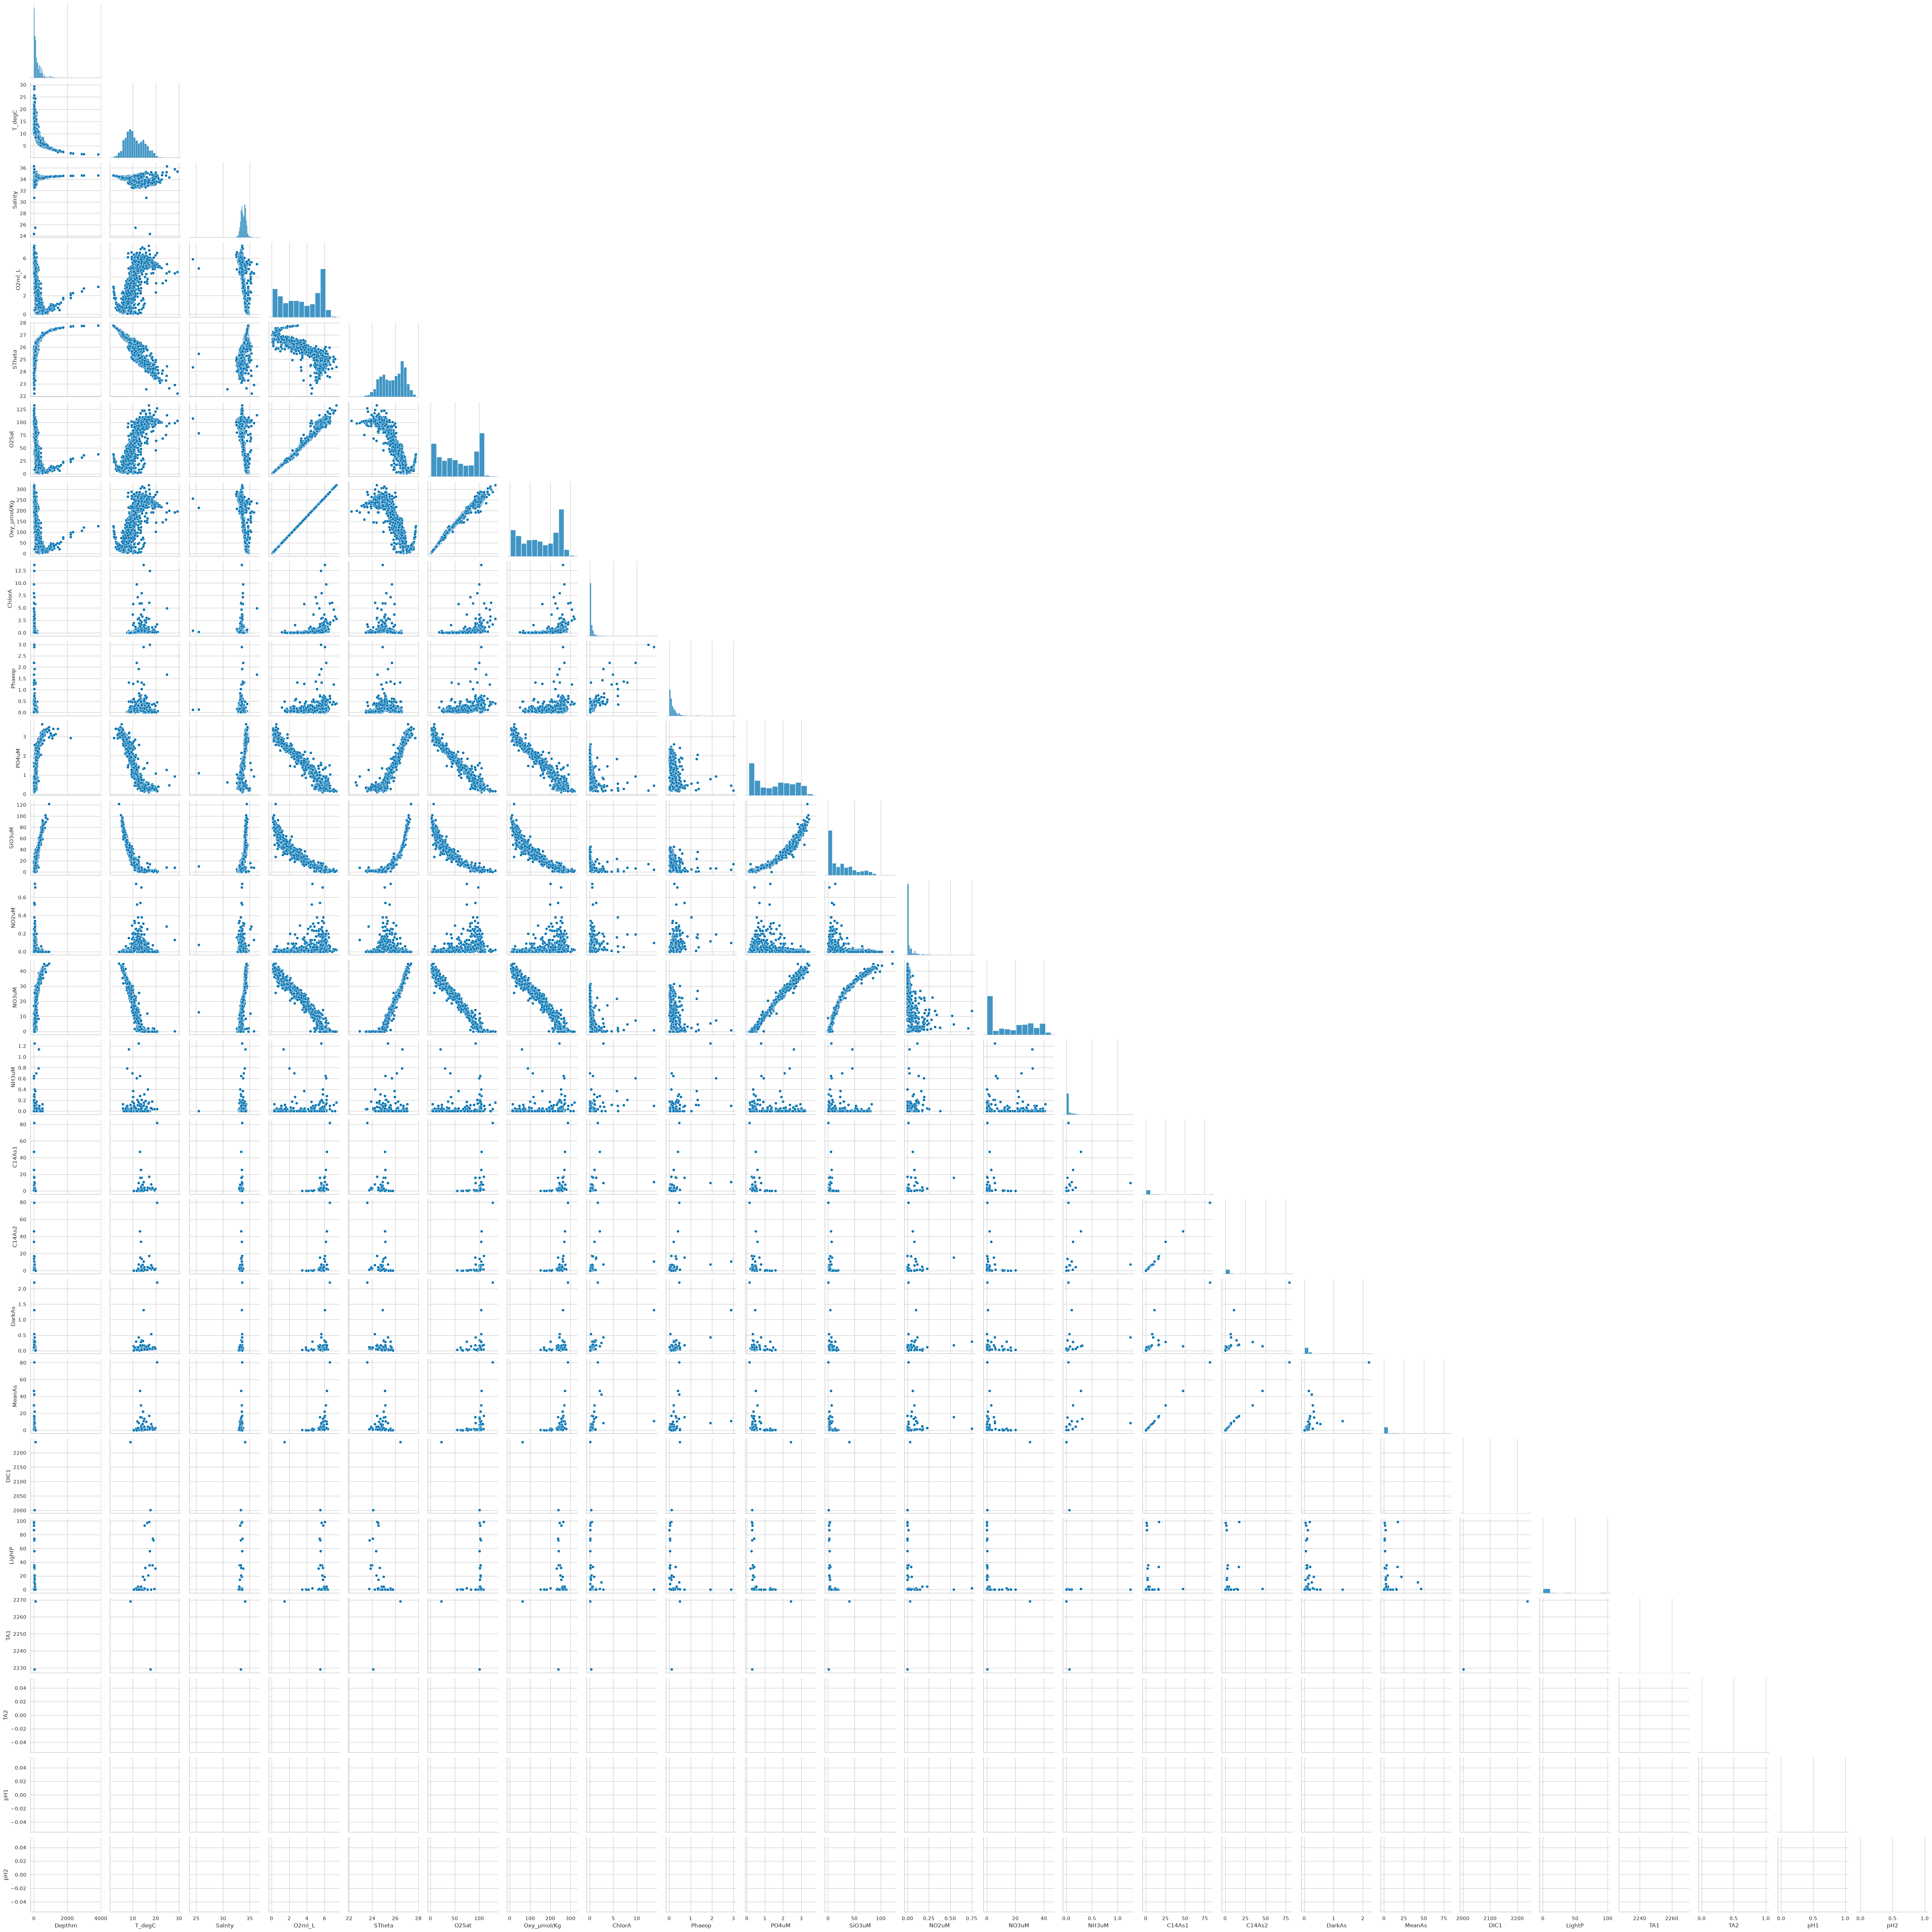

In [36]:
# Pairplot on full CalCOFI bottle table is too heavy; use a small sample
_pair_sample = (
    df[bottle_numeric_features]
    .dropna(how="all")
    .sample(n=min(2000, len(df)), random_state=42)
)
sns.pairplot(_pair_sample, corner=True)
plt.show()

In [37]:
cast.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35644 entries, 0 to 35643
Data columns (total 61 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Cst_Cnt      35644 non-null  int64  
 1   Cruise_ID    35644 non-null  object 
 2   Cruise       35644 non-null  int64  
 3   Cruz_Sta     35644 non-null  int64  
 4   DbSta_ID     35644 non-null  int64  
 5   Cast_ID      35644 non-null  object 
 6   Sta_ID       35644 non-null  object 
 7   Quarter      35644 non-null  int64  
 8   Sta_Code     35644 non-null  object 
 9   Distance     20954 non-null  float64
 10  Date         35644 non-null  object 
 11  Year         35644 non-null  int64  
 12  Month        35644 non-null  int64  
 13  Julian_Date  35644 non-null  int64  
 14  Julian_Day   35644 non-null  int64  
 15  Time         35320 non-null  object 
 16  Lat_Dec      35644 non-null  float64
 17  Lat_Deg      35644 non-null  int64  
 18  Lat_Min      35644 non-null  float64
 19  Lat_

In [38]:
whatis('IntChl',cast_desc)

40    Integrated Chlorophyll per half light day
Name: Description, dtype: object


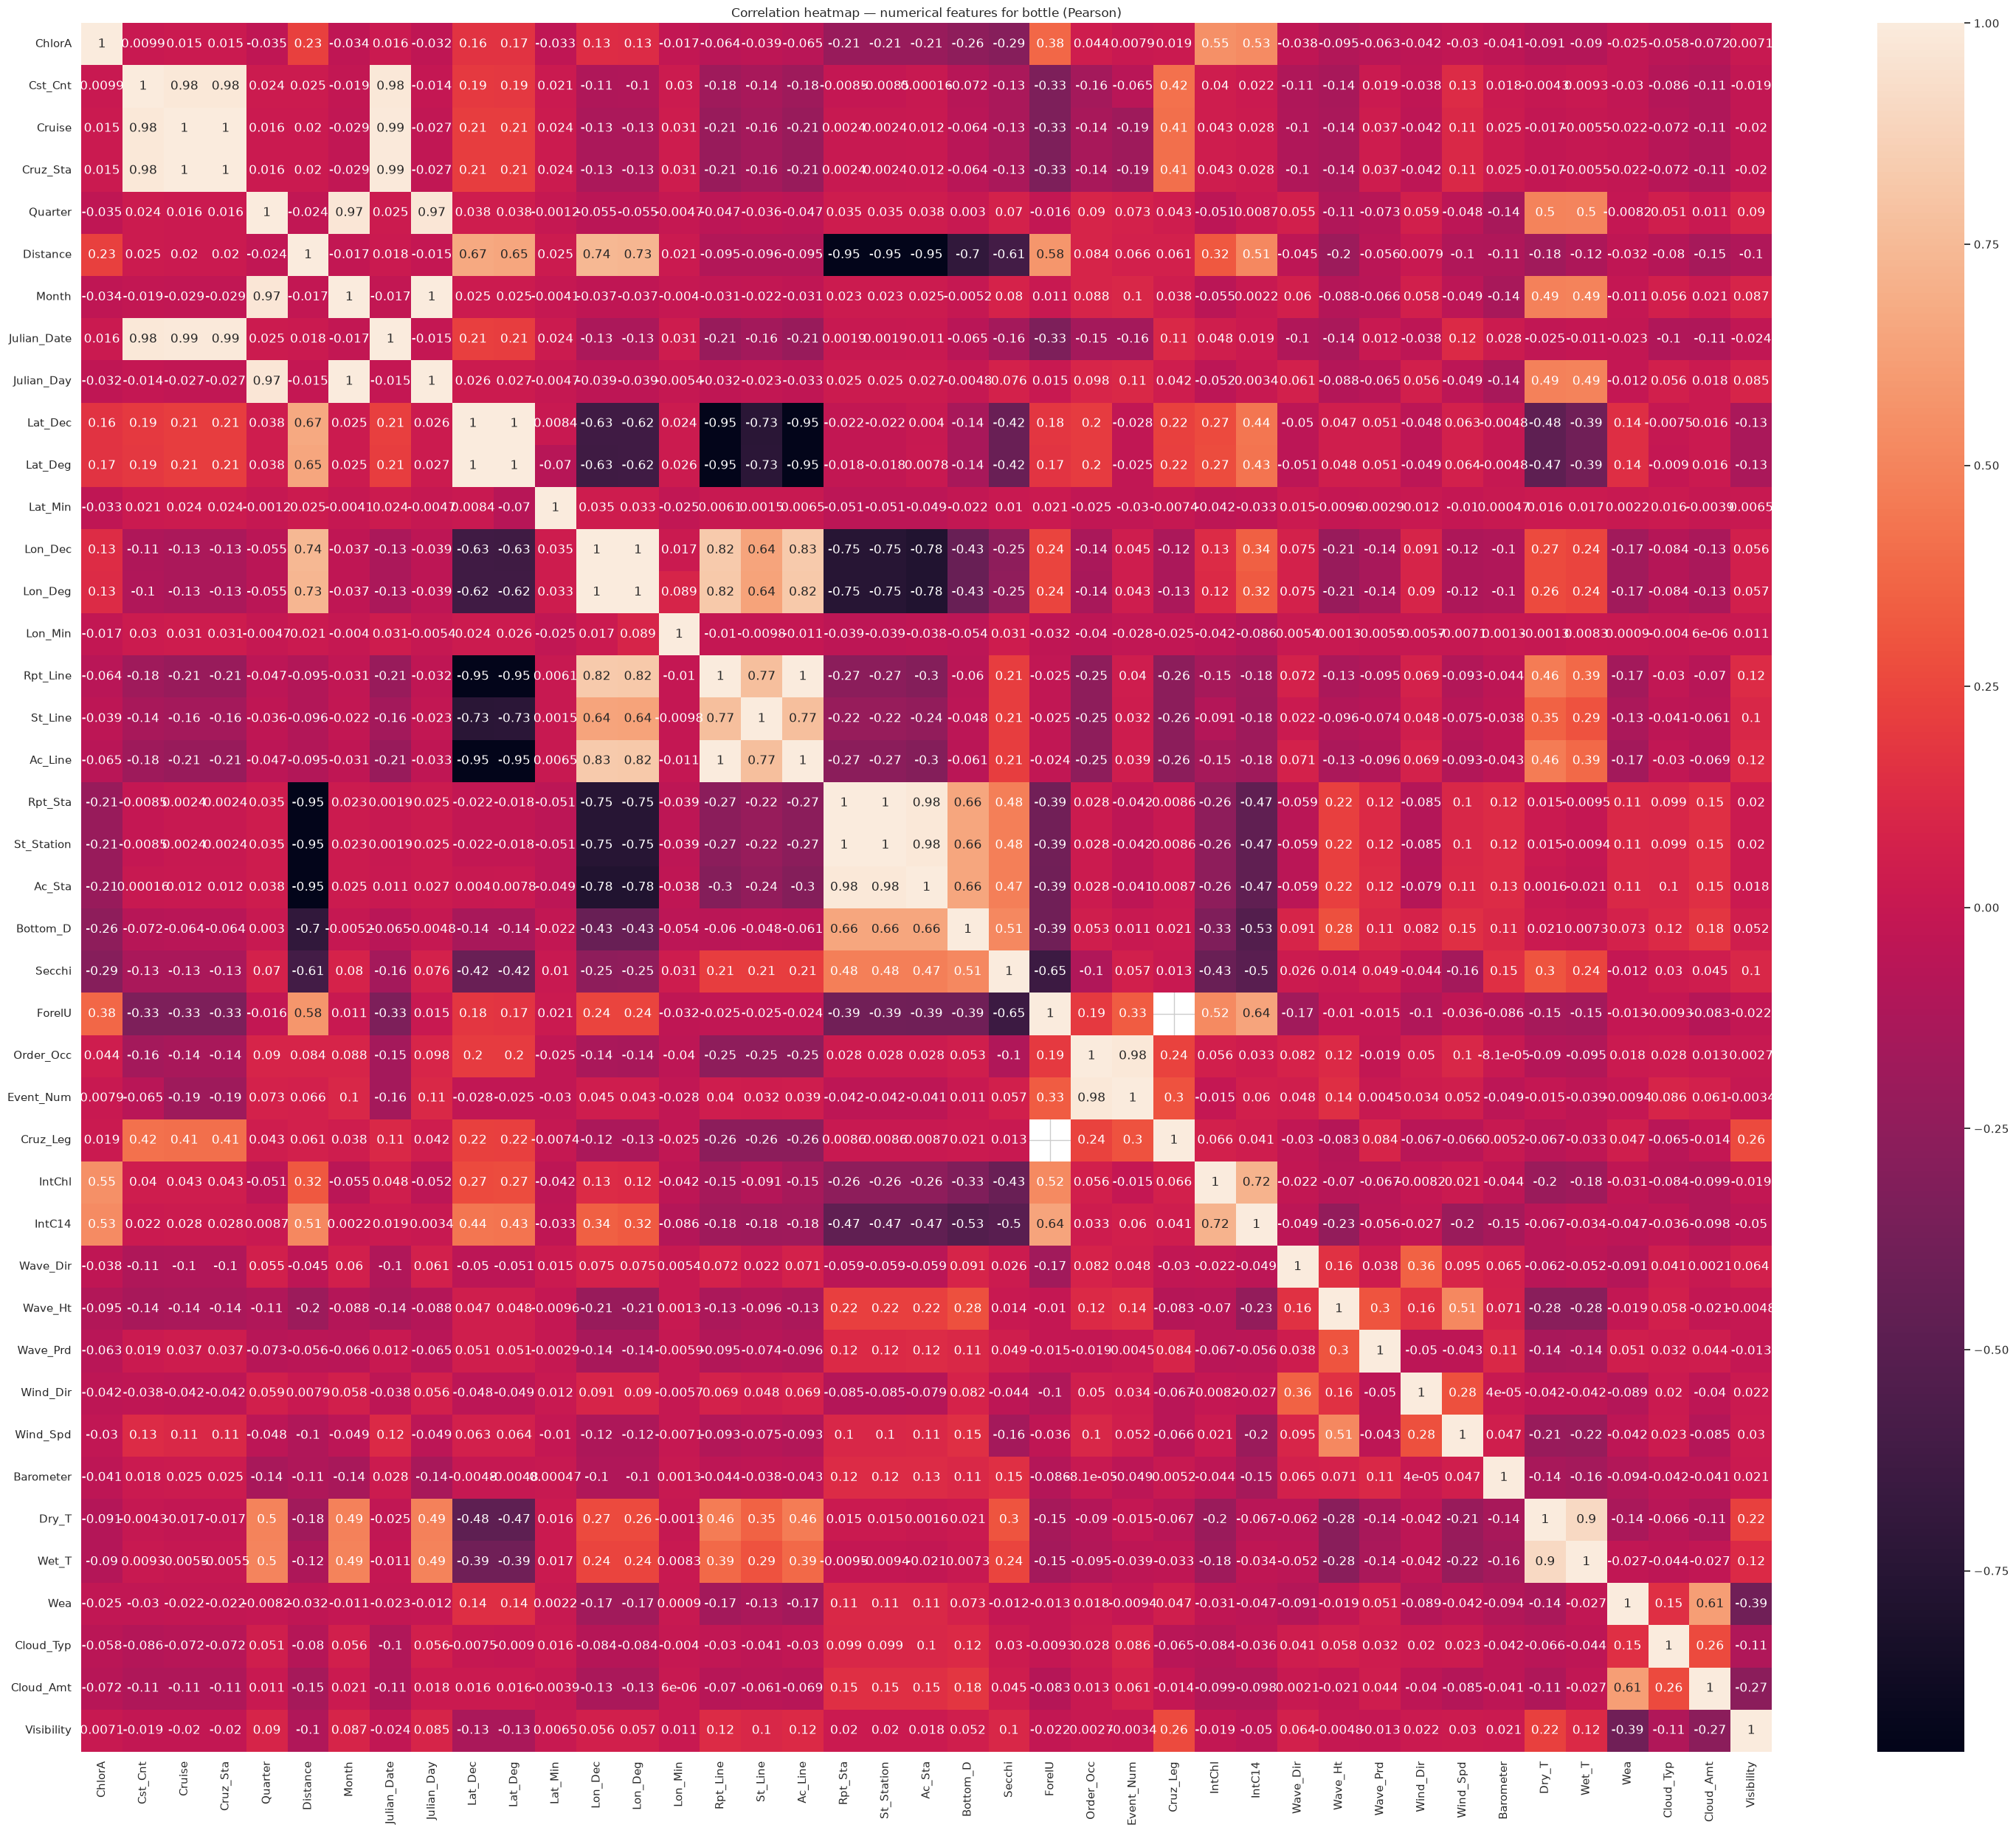

Top |correlations| with ChlorA:


,corr_with_ChlorA
IntChl,0.553275
IntC14,0.526864
ForelU,0.376568
Secchi,-0.292312
Bottom_D,-0.257508
Distance,0.225642
Ac_Sta,-0.207882
Rpt_Sta,-0.207412
St_Station,-0.207406
Lat_Deg,0.165302


In [39]:
cast_numeric_features = ['ChlorA','Cst_Cnt','Cruise', 'Cruz_Sta', 'Quarter', 'Sta_Code', 'Distance', 'Month',
       'Julian_Date', 'Julian_Day', 'Time', 'Lat_Dec', 'Lat_Deg', 'Lat_Min',
        'Lon_Dec', 'Lon_Deg', 'Lon_Min', 'Rpt_Line',
       'St_Line', 'Ac_Line', 'Rpt_Sta', 'St_Station', 'Ac_Sta', 'Bottom_D',
       'Secchi', 'ForelU', 'Ship_Name', 'Ship_Code', 'Data_Type', 'Order_Occ',
       'Event_Num', 'Cruz_Leg', 'Orig_Sta_ID', 'Data_Or', 'Cruz_Num', 'IntChl',
       'IntC14', 
       'Wave_Dir', 'Wave_Ht', 'Wave_Prd', 'Wind_Dir', 'Wind_Spd', 'Barometer',
       'Dry_T', 'Wet_T', 'Wea', 'Cloud_Typ', 'Cloud_Amt', 'Visibility']

corr = df[cast_numeric_features].corr(method="pearson",numeric_only=True)

fig, ax = plt.subplots(figsize=(30, 25))
sns.heatmap(
    corr,
    annot=True

)
ax.set_title("Correlation heatmap — numerical features for bottle (Pearson)")
plt.tight_layout()
plt.show()

# ChlorA correlations ranked
if "ChlorA" in corr.columns:
    chlora_corr = corr["ChlorA"].drop("ChlorA").sort_values(key=abs, ascending=False)
    print("Top |correlations| with ChlorA:")
    display(chlora_corr.head(15).to_frame("corr_with_ChlorA"))

In [40]:
whatis('IntChl',cast_desc)

40    Integrated Chlorophyll per half light day
Name: Description, dtype: object


In [41]:
whatis('IntC14',cast_desc)

41    Integrated Primary Productivity per half light day
Name: Description, dtype: object


In [42]:
whatis('ForelU',cast_desc)

60    Water color; Only used in CalCOFI dataset from 1988-10 through 1998-04
Name: Description, dtype: object


In [43]:
whatis('Secchi',cast_desc)

59    Secchi disk depth in meters
Name: Description, dtype: object


In [44]:
whatis('Bottom_D',cast_desc)

30    Bottom depth in meters
Name: Description, dtype: object


In [45]:
whatis('Wave_Ht',cast_desc)

48    Wave Height in feet
Name: Description, dtype: object


In [46]:
whatis('Dry_T',cast_desc)

53    Dry Air Temperature from a Sling Psychrometer in degrees Celcius
Name: Description, dtype: object


### 4.2 Distance from coast vs ChlorA (hue = Month)

`Distance` is nautical miles from the coast intercept (cast-level). Colored by calendar month to show seasonal structure.

Rows with Distance + ChlorA + Month: 225,955


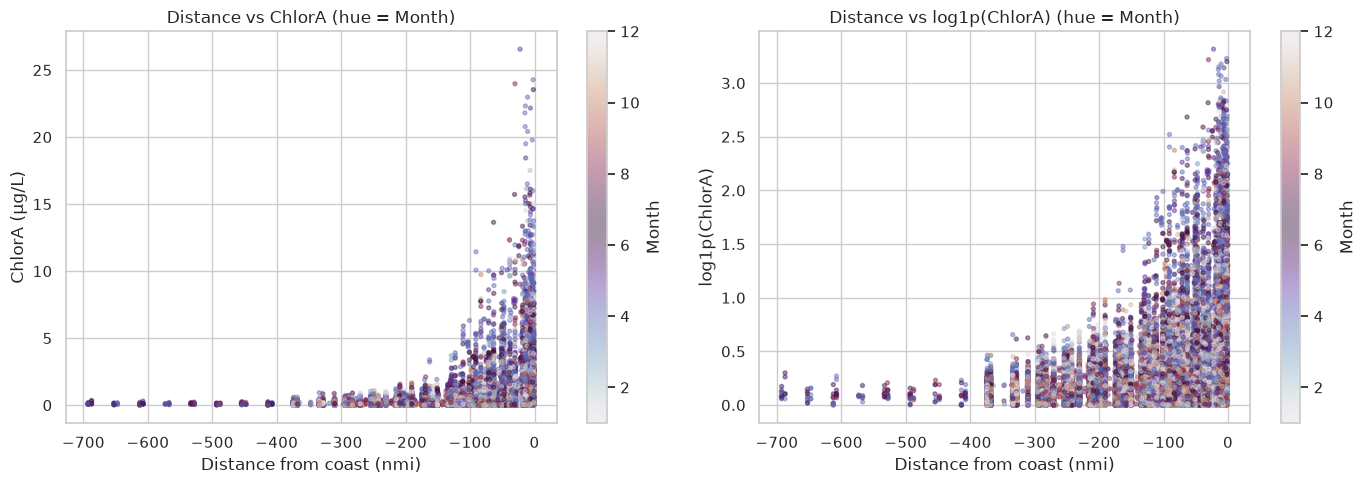

,n,mean_ChlorA,mean_Distance
Month,,,
1,36018,0.361627,-128.184559
2,16930,0.403491,-120.227542
3,11468,0.388642,-121.450509
4,39528,0.650074,-128.740015
5,10166,0.703472,-113.294446
6,4000,0.466945,-150.447996
7,32808,0.466763,-128.538742
8,17616,0.421576,-131.293397
9,6884,0.285859,-135.723588


In [47]:
dist_plot = eda[["Distance", "ChlorA", "Month"]].dropna()
print(f"Rows with Distance + ChlorA + Month: {len(dist_plot):,}")

# Sample for readability if very large
if len(dist_plot) > 40_000:
    dist_plot = dist_plot.sample(40_000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter: Distance vs ChlorA, colored by month
sc = axes[0].scatter(
    dist_plot["Distance"],
    dist_plot["ChlorA"],
    c=dist_plot["Month"],
    cmap="twilight",
    s=8,
    alpha=0.45,
)
cb = fig.colorbar(sc, ax=axes[0], label="Month")
axes[0].set_xlabel("Distance from coast (nmi)")
axes[0].set_ylabel("ChlorA (µg/L)")
axes[0].set_title("Distance vs ChlorA (hue = Month)")

# Same relationship on log1p(ChlorA) — chlorophyll is heavily right-skewed
sc2 = axes[1].scatter(
    dist_plot["Distance"],
    np.log1p(dist_plot["ChlorA"]),
    c=dist_plot["Month"],
    cmap="twilight",
    s=8,
    alpha=0.45,
)
fig.colorbar(sc2, ax=axes[1], label="Month")
axes[1].set_xlabel("Distance from coast (nmi)")
axes[1].set_ylabel("log1p(ChlorA)")
axes[1].set_title("Distance vs log1p(ChlorA) (hue = Month)")

plt.tight_layout()
plt.show()

# Monthly summary
monthly = (
    eda.dropna(subset=["Distance", "ChlorA", "Month"])
    .groupby("Month")
    .agg(n=("ChlorA", "size"), mean_ChlorA=("ChlorA", "mean"), mean_Distance=("Distance", "mean"))
)
display(monthly)

## 5. Feature engineering & missing values

Fill NAs using the cast-wise approach from the latest PR, extended to all bottle numeric features:

1. Within-cast **linear interpolation** (same as T_degC / Salnty / O2ml_L)
2. Residual gaps: **mean** if roughly Gaussian/symmetric (|skew| < 0.5), else **median**
3. Derive **Line / Station**, **NSM**, and one-hot encode **Month** and **Day**


In [48]:
# Resolve oxygen column names (mu character can vary by encoding)
def col_containing(df, *parts):
    for c in df.columns:
        if all(p in c for p in parts):
            return c
    raise KeyError(f"No column containing {parts}")

OXY_UMOL = col_containing(df, "Oxy_", "mol/Kg")
R_OXY_UMOL = col_containing(df, "R_Oxy")

TOP_CORR_FEATURES = [
    "Phaeop",
    R_OXY_UMOL,
    OXY_UMOL,
    "O2ml_L",
    "Depthm",
    "R_Depth",
    "R_DYNHT",
    "O2Sat",
    "SiO3uM",
    "NO3uM",
    "T_degC",
]

print("Top-correlation feature columns:")
for c in TOP_CORR_FEATURES:
    print(f"  {c!r}")

# Work only on rows with ChlorA target
model_df = df[df["ChlorA"].notna()].copy()

# --- Line & Station from Sta_ID ("090.0 045.0") ---
sta_parts = model_df["Sta_ID"].astype(str).str.strip().str.split(expand=True)
model_df["Line"] = pd.to_numeric(sta_parts[0], errors="coerce")
model_df["Station"] = pd.to_numeric(sta_parts[1], errors="coerce")

# --- Day of month from Date; NSM from Time ---
model_df["Date_parsed"] = pd.to_datetime(model_df["Date"], errors="coerce")
model_df["Day"] = model_df["Date_parsed"].dt.day

def time_to_nsm(t):
    """Number of Seconds since Midnight."""
    if pd.isna(t):
        return np.nan
    try:
        parts = str(t).split(":")
        h, m = int(parts[0]), int(parts[1])
        s = float(parts[2]) if len(parts) > 2 else 0.0
        return h * 3600 + m * 60 + s
    except Exception:
        return np.nan

model_df["NSM"] = model_df["Time"].map(time_to_nsm)

print(f"Rows with ChlorA: {len(model_df):,}")
print("NA rates (before impute) for top correlates + time/location:")
display(
    model_df[TOP_CORR_FEATURES + ["Line", "Station", "Month", "Day", "NSM"]]
    .isna().mean()
    .sort_values(ascending=False)
    .to_frame("frac_na")
)

Top-correlation feature columns:
  'Phaeop'
  'R_Oxy_µmol/Kg'
  'Oxy_µmol/Kg'
  'O2ml_L'
  'Depthm'
  'R_Depth'
  'R_DYNHT'
  'O2Sat'
  'SiO3uM'
  'NO3uM'
  'T_degC'
Rows with ChlorA: 245,666
NA rates (before impute) for top correlates + time/location:


,frac_na
NO3uM,0.043661
SiO3uM,0.041117
R_Oxy_µmol/Kg,0.018415
Oxy_µmol/Kg,0.018415
O2Sat,0.018403
O2ml_L,0.014788
R_DYNHT,0.014434
T_degC,0.012590
Phaeop,0.000020
R_Depth,0.000004


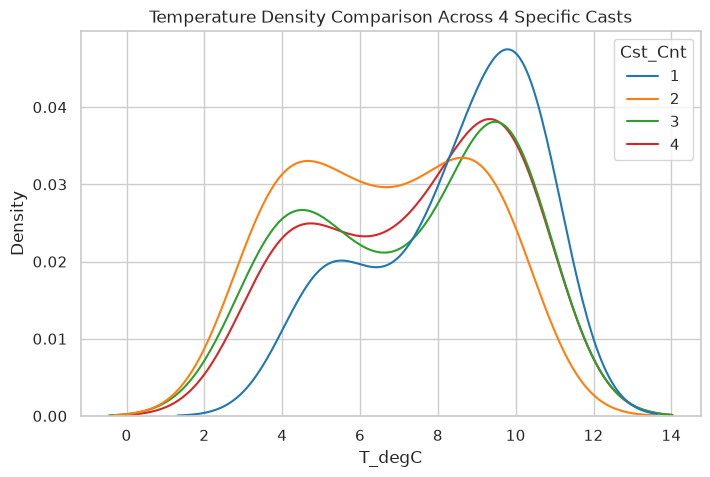

In [49]:
# Select 4 specific casts
selected_casts = df['Cst_Cnt'].unique()[:4]
subset = df[df['Cst_Cnt'].isin(selected_casts)]

plt.figure(figsize=(8, 5))
sns.kdeplot(data=subset, x="T_degC", hue="Cst_Cnt", palette="tab10")
plt.title("Temperature Density Comparison Across 4 Specific Casts")
plt.show()

In [50]:
df.shape

(895371, 121)

In [51]:
df['T_degC'].isna().sum()/df.shape[0]

np.float64(0.012250787662320982)

In [52]:
df['T_degC'] = df.groupby('Cst_Cnt')['T_degC'].transform(lambda group: group.interpolate(method='linear',limit_direction='both'))

In [53]:
df['T_degC'].isna().sum()

np.int64(2683)

In [54]:
# Select 4 specific casts
selected_casts = df[df['T_degC'].isna()]['Cst_Cnt']
subset = df[df['Cst_Cnt'].isin(selected_casts)]

print(subset['T_degC'].unique()) 
print(subset['Ship_Name'].unique()) 
print(subset['Date'].unique()) 

display(subset.head(10))

[nan]
['RV NEW HORIZON' 'RV DAVID STARR JORDAN']
['01/05/1984' '01/06/1984' '01/07/1984' '01/08/1984' '01/09/1984'
 '01/10/1984' '01/11/1984' '01/12/1984' '01/13/1984' '01/14/1984'
 '01/15/1984' '01/16/1984' '01/17/1984' '01/18/1984' '01/19/1984'
 '01/20/1984' '01/21/1984' '01/22/1984' '01/23/1984' '01/24/1984'
 '01/26/1984' '02/08/1984' '02/09/1984' '02/10/1984' '02/11/1984'
 '02/12/1984' '02/13/1984' '02/14/1984' '02/15/1984' '02/16/1984'
 '02/17/1984' '02/18/1984' '02/19/1984' '02/20/1984' '02/21/1984'
 '02/22/1984' '02/26/1984' '02/27/1984' '02/28/1984' '02/29/1984'
 '03/01/1984' '03/02/1984' '02/23/1984' '02/24/1984' '02/25/1984'
 '03/03/1984' '03/04/1984' '03/05/1984' '03/06/1984' '03/07/1984'
 '03/08/1984' '03/09/1984' '03/10/1984' '03/13/1984' '03/14/1984'
 '03/15/1984' '03/16/1984' '03/17/1984' '03/18/1984' '03/19/1984'
 '03/20/1984' '03/21/1984' '03/22/1984' '03/23/1984' '03/24/1984'
 '03/25/1984' '03/26/1984' '03/27/1984' '03/28/1984' '04/10/1984'
 '04/11/1984' '04/12/1984' 

,Cst_Cnt,Btl_Cnt,Sta_ID,Depth_ID,Depthm,T_degC,Salnty,O2ml_L,STheta,O2Sat,Oxy_µmol/Kg,BtlNum,RecInd,T_prec,T_qual,S_prec,S_qual,P_qual,O_qual,SThtaq,O2Satq,ChlorA,Chlqua,Phaeop,Phaqua,PO4uM,PO4q,SiO3uM,SiO3qu,NO2uM,NO2q,NO3uM,NO3q,NH3uM,NH3q,C14As1,C14A1p,C14A1q,C14As2,C14A2p,...,Lon_Deg,Lon_Min,Lon_Hem,Rpt_Line,St_Line,Ac_Line,Rpt_Sta,St_Station,Ac_Sta,Bottom_D,Secchi,ForelU,Ship_Name,Ship_Code,Data_Type,Order_Occ,Event_Num,Cruz_Leg,Orig_Sta_ID,Data_Or,Cruz_Num,IntChl,IntC14,Inc_Str,Inc_End,PST_LAN,Civil_T,TimeZone,Wave_Dir,Wave_Ht,Wave_Prd,Wind_Dir,Wind_Spd,Barometer,Dry_T,Wet_T,Wea,Cloud_Typ,Cloud_Amt,Visibility
553767,22526,553768,090.0 032.0,19-8401NM-PR-005-1806-09000320-0000B-3,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN,9.0,NaN,9.0,9.0,9.0,9.0,9.0,0.24,NaN,0.09,NaN,0.33,NaN,2.0,NaN,0.00,NaN,0.2,NaN,NaN,9.0,2.30,1.0,NaN,2.4,1.0,...,-118,2.5,W,90.0,90.0,90.0,32.0,32.0,32.0,558.0,25.0,NaN,RV NEW HORIZON,32NM,PR,NaN,3503.0,NaN,90 32,3101,8401,39.3,385.1,11:00:00 AM,5:42:00 PM,11:57:00 AM,5:26:00 PM,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
553768,22526,553769,090.0 032.0,19-8401NM-PR-005-1806-09000320-0010A-7,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7,NaN,9.0,NaN,9.0,9.0,9.0,9.0,9.0,0.25,NaN,0.09,NaN,0.33,NaN,1.9,NaN,0.00,NaN,0.2,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-118,2.5,W,90.0,90.0,90.0,32.0,32.0,32.0,558.0,25.0,NaN,RV NEW HORIZON,32NM,PR,NaN,3503.0,NaN,90 32,3101,8401,39.3,385.1,11:00:00 AM,5:42:00 PM,11:57:00 AM,5:26:00 PM,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
553769,22526,553770,090.0 032.0,19-8401NM-PR-005-1806-09000320-0019A-3,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN,9.0,NaN,9.0,9.0,9.0,9.0,9.0,0.25,NaN,0.09,NaN,0.33,NaN,1.9,NaN,0.00,NaN,0.2,NaN,NaN,9.0,4.80,1.0,NaN,5.7,1.0,...,-118,2.5,W,90.0,90.0,90.0,32.0,32.0,32.0,558.0,25.0,NaN,RV NEW HORIZON,32NM,PR,NaN,3503.0,NaN,90 32,3101,8401,39.3,385.1,11:00:00 AM,5:42:00 PM,11:57:00 AM,5:26:00 PM,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
553770,22526,553771,090.0 032.0,19-8401NM-PR-005-1806-09000320-0020A-7,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7,NaN,9.0,NaN,9.0,9.0,9.0,9.0,9.0,0.25,NaN,0.09,NaN,0.33,NaN,1.9,NaN,0.00,NaN,0.2,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-118,2.5,W,90.0,90.0,90.0,32.0,32.0,32.0,558.0,25.0,NaN,RV NEW HORIZON,32NM,PR,NaN,3503.0,NaN,90 32,3101,8401,39.3,385.1,11:00:00 AM,5:42:00 PM,11:57:00 AM,5:26:00 PM,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
553771,22526,553772,090.0 032.0,19-8401NM-PR-005-1806-09000320-0026A-3,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN,9.0,NaN,9.0,9.0,9.0,9.0,9.0,0.24,NaN,0.09,NaN,0.33,NaN,1.8,NaN,0.00,NaN,0.2,NaN,NaN,9.0,7.10,1.0,NaN,6.6,1.0,...,-118,2.5,W,90.0,90.0,90.0,32.0,32.0,32.0,558.0,25.0,NaN,RV NEW HORIZON,32NM,PR,NaN,3503.0,NaN,90 32,3101,8401,39.3,385.1,11:00:00 AM,5:42:00 PM,11:57:00 AM,5:26:00 PM,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
553772,22526,553773,090.0 032.0,19-8401NM-PR-005-1806-09000320-0030A-7,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7,NaN,9.0,NaN,9.0,9.0,9.0,9.0,9.0,0.55,NaN,0.24,NaN,0.38,NaN,2.2,NaN,0.02,NaN,0.4,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-118,2.5,W,90.0,90.0,90.0,32.0,32.0,32.0,558.0,25.0,NaN,RV NEW HORIZON,32NM,PR,NaN,3503.0,NaN,90 32,3101,8401,39.3,385.1,11:00:00 AM,5:42:00 PM,11:57:00 AM,5:26:00 PM,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
553773,22526,553774,090.0 032.0,19-8401NM-PR-005-1806-09000320-0038A-3,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN,9.0,NaN,9.0,9.0,9.0,9.0,9.0,1.24,NaN,0.59,NaN,0.51,NaN,3.3,NaN,0.08,NaN,1.1,NaN,NaN,9.0,8.70,1.0,NaN,10.1,1.0,...,-118,2.5,W,90.0,90.0,90.0,32.0,32.0,32.0,558.0,25.0,NaN,RV NEW HORIZON,32NM,PR,NaN,3503.0,NaN,90 32,3101,8401,39.3,385.1,11:00:00 AM,5:42:00 PM,11:57:00 AM,5:26:00 PM,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
553774,22526,553775,090.0 032.0,19-8401NM-PR-005-1806-09000320-0050A-7,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7,NaN,9.0,NaN,9.0,9.0,9.0,9.0,9.0,1.07,NaN,0.45,NaN,0.64,NaN,4.2,NaN,0.06,NaN,2.8,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-118,2.5,W,90.0,90.0,90.0,32.0,32.0,32.0,558.0,25.0,NaN,RV NEW HORIZON,32NM,PR,N

This tells that both ships at the give dates didnt have the sensor required to measure tempertaure salinity, 02 sat

In [55]:
df[df['Date'].isin(subset['Date'].unique())]['Ship_Name'].unique()

array(['RV NEW HORIZON', 'RV DAVID STARR JORDAN'], dtype=object)

In [56]:
df[df['Date'].isin(subset['Date'].unique())]['T_degC'].count()

np.int64(30126)

In [57]:
df[df['Date'].isin(subset['Date'].unique())]['T_degC'].isna().sum()

np.int64(2683)

In [58]:
df.dropna(subset=['T_degC'],inplace=True)

dropping these na values would suffice

In [59]:
df['Depthm'].isna().sum()

np.int64(0)

checking next columns to be filled

In [60]:
for col in bottle_numeric_features:
    print(col , ":",df[col].isna().sum())

Depthm : 0
T_degC : 0
Salnty : 44798
O2ml_L : 167250
STheta : 50013
O2Sat : 201942
Oxy_µmol/Kg : 201990
ChlorA : 649687
Phaeop : 649688
PO4uM : 452557
SiO3uM : 511782
NO2uM : 529025
NO3uM : 528469
NH3uM : 802199
C14As1 : 878754
C14As2 : 878752
DarkAs : 871584
MeanAs : 871583
DIC1 : 890689
LightP : 875594
TA1 : 890604
TA2 : 892454
pH1 : 892604
pH2 : 892678


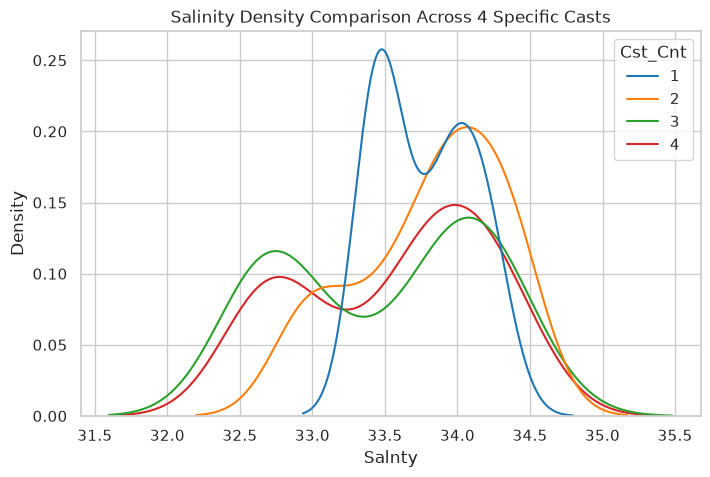

In [61]:
# Select 4 specific casts
selected_casts = df['Cst_Cnt'].unique()[:4]
subset = df[df['Cst_Cnt'].isin(selected_casts)]

plt.figure(figsize=(8, 5))
sns.kdeplot(data=subset, x="Salnty", hue="Cst_Cnt", palette="tab10")
plt.title("Salinity Density Comparison Across 4 Specific Casts")
plt.show()

In [62]:
# Select 4 specific casts
selected_casts = df[df['Salnty'].isna()]['Cst_Cnt']
subset = df[df['Cst_Cnt'].isin(selected_casts)]
print(subset['Cst_Cnt'].unique())
print(subset['Salnty'].unique()) 
print(subset['Ship_Name'].unique()) 
print(subset['Date'].unique()) 

display(subset.head(10))

[    1     4     5 ... 32980 35043 35437]
[33.44   33.437  33.42   ... 34.2832 34.2786 34.2851]
['CREST' 'HORIZON' 'MV N.B. SCOFIELD' 'BLACK DOUGLAS' 'PAOLINA-T'
 'E.W. SCRIPPS' 'YELLOWFIN' 'SPENCER F. BAIRD' 'STRANGER' 'ORCA'
 'H.M. SMITH' 'RV ALEXANDER AGASSIZ' 'RV DAVID STARR JORDAN'
 'ELLEN B. SCRIPPS' 'RV Alaska' 'DAVID PHILLIP DOLPHIN'
 'RV ALEJANDRO DE HUMBOLDT' 'RV NEW HORIZON' 'TOWNSEND CROMWELL'
 'MCARTHUR' 'RV ROGER REVELLE' 'RV New Horizon' 'RV BELL M SHIMADA'
 'RV REUBEN LASKER' 'RV SALLY RIDE']
['03/01/1949' '03/02/1949' '03/04/1949' ... '03/30/2012' '02/11/2019'
 '07/14/2020']


,Cst_Cnt,Btl_Cnt,Sta_ID,Depth_ID,Depthm,T_degC,Salnty,O2ml_L,STheta,O2Sat,Oxy_µmol/Kg,BtlNum,RecInd,T_prec,T_qual,S_prec,S_qual,P_qual,O_qual,SThtaq,O2Satq,ChlorA,Chlqua,Phaeop,Phaqua,PO4uM,PO4q,SiO3uM,SiO3qu,NO2uM,NO2q,NO3uM,NO3q,NH3uM,NH3q,C14As1,C14A1p,C14A1q,C14As2,C14A2p,...,Lon_Deg,Lon_Min,Lon_Hem,Rpt_Line,St_Line,Ac_Line,Rpt_Sta,St_Station,Ac_Sta,Bottom_D,Secchi,ForelU,Ship_Name,Ship_Code,Data_Type,Order_Occ,Event_Num,Cruz_Leg,Orig_Sta_ID,Data_Or,Cruz_Num,IntChl,IntC14,Inc_Str,Inc_End,PST_LAN,Civil_T,TimeZone,Wave_Dir,Wave_Ht,Wave_Prd,Wind_Dir,Wind_Spd,Barometer,Dry_T,Wet_T,Wea,Cloud_Typ,Cloud_Amt,Visibility
0,1,1,054.0 056.0,19-4903CR-HY-060-0930-05400560-0000A-3,0,10.50,33.440,NaN,25.649,NaN,NaN,NaN,3,1.0,NaN,2.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
1,1,2,054.0 056.0,19-4903CR-HY-060-0930-05400560-0008A-3,8,10.46,33.440,NaN,25.656,NaN,NaN,NaN,3,2.0,NaN,2.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
2,1,3,054.0 056.0,19-4903CR-HY-060-0930-05400560-0010A-7,10,10.46,33.437,NaN,25.654,NaN,NaN,NaN,7,2.0,NaN,3.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
3,1,4,054.0 056.0,19-4903CR-HY-060-0930-05400560-0019A-3,19,10.45,33.420,NaN,25.643,NaN,NaN,NaN,3,2.0,NaN,2.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
4,1,5,054.0 056.0,19-4903CR-HY-060-0930-05400560-0020A-7,20,10.45,33.421,NaN,25.643,NaN,NaN,NaN,7,2.0,NaN,3.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
5,1,6,054.0 056.0,19-4903CR-HY-060-0930-05400560-0030A-7,30,10.45,33.431,NaN,25.651,NaN,NaN,NaN,7,2.0,NaN,3.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
6,1,7,054.0 056.0,19-4903CR-HY-060-0930-05400560-0039A-3,39,10.45,33.440,NaN,25.658,NaN,NaN,NaN,3,2.0,NaN,2.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
7,1,8,054.0 056.0,19-4903CR-HY-060-0930-05400560-0050A-7,50,10.24,33.424,NaN,25.682,NaN,NaN,NaN,7,2.0,NaN,3.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
8,1,9,054.0 056.0,19-4903CR-HY-060-0930-05400560-0058A-3,58,10.06,33.420,NaN,25.710,NaN,NaN,NaN,3,2.0,NaN,2.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,Na

In [63]:
df[df['Cst_Cnt'].isin(subset['Cst_Cnt'])]['Salnty'].count()

np.int64(70433)

In [64]:
df[df['Cst_Cnt'].isin(subset['Cst_Cnt'])]['Salnty'].isna().sum()

np.int64(44798)

In [65]:
df['Salnty'] = df.groupby('Cst_Cnt')['Salnty'].transform(lambda group: group.interpolate(method='linear',limit_direction='both'))

In [66]:
df['Salnty'].isna().sum()

np.int64(13722)

In [67]:
df['O2ml_L'].isna().sum()

np.int64(167250)

In [68]:
whatis('O2ml_L',bottle_desc)

7    Milliliters oxygen per liter of seawater
Name: Description, dtype: object


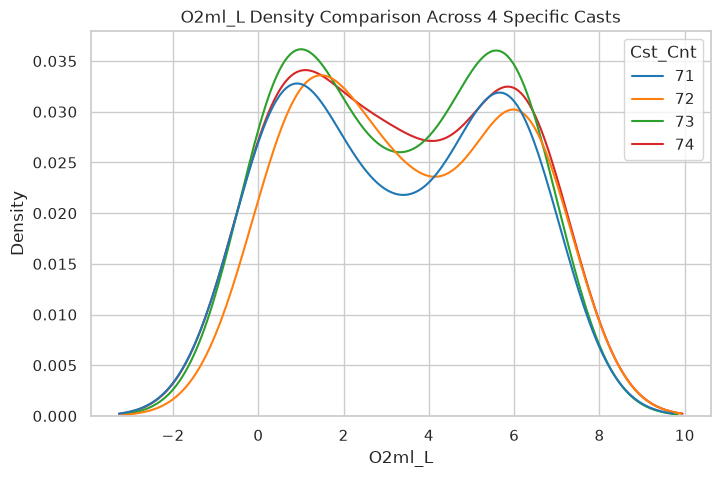

In [69]:
# Select 4 specific casts
selected_casts = df[df['O2ml_L'].notna()]['Cst_Cnt'].unique()[:4]
subset = df[df['Cst_Cnt'].isin(selected_casts)]

plt.figure(figsize=(8, 5))
sns.kdeplot(data=subset, x="O2ml_L", hue="Cst_Cnt", palette="tab10")
plt.title("O2ml_L Density Comparison Across 4 Specific Casts")
plt.show()

In [70]:
(df['O2ml_L'].isna().sum()/df.shape[0])*100

np.float64(18.735549262452277)

In [71]:
df['O2ml_L'] = df.groupby('Cst_Cnt')['O2ml_L'].transform(lambda group: group.interpolate(method='linear',limit_direction='both'))

In [72]:
(df['O2ml_L'].isna().sum()/df.shape[0])*100

np.float64(17.290475507680174)

In [73]:
# Select 4 specific casts
selected_casts = df[df['O2ml_L'].isna()]['Cst_Cnt']
subset = df[df['Cst_Cnt'].isin(selected_casts)]
print(subset['Cst_Cnt'].unique())
print(subset['Salnty'].unique()) 
print(subset['Ship_Name'].unique()) 
print(subset['Date'].unique()) 

display(subset.head(10))

[    1     2     3 ... 32242 32244 32246]
[33.44  33.437 33.42  ... 32.357 32.259 35.462]
['CREST' 'HORIZON' 'MV N.B. SCOFIELD' 'BLACK DOUGLAS' 'PAOLINA-T'
 'E.W. SCRIPPS' 'YELLOWFIN' 'SPENCER F. BAIRD' 'STRANGER' 'ORCA'
 'H.M. SMITH' 'RV ALEXANDER AGASSIZ' 'RV DAVID STARR JORDAN'
 'ELLEN B. SCRIPPS' 'MILLER FREEMAN' 'RV Alaska'
 'RV ALEJANDRO DE HUMBOLDT' 'RV NEW HORIZON' 'TOWNSEND CROMWELL'
 'RV ROGER REVELLE' 'MCARTHUR']
['03/01/1949' '03/02/1949' '03/03/1949' ... '08/02/2009' '02/02/2010'
 '02/03/2010']


,Cst_Cnt,Btl_Cnt,Sta_ID,Depth_ID,Depthm,T_degC,Salnty,O2ml_L,STheta,O2Sat,Oxy_µmol/Kg,BtlNum,RecInd,T_prec,T_qual,S_prec,S_qual,P_qual,O_qual,SThtaq,O2Satq,ChlorA,Chlqua,Phaeop,Phaqua,PO4uM,PO4q,SiO3uM,SiO3qu,NO2uM,NO2q,NO3uM,NO3q,NH3uM,NH3q,C14As1,C14A1p,C14A1q,C14As2,C14A2p,...,Lon_Deg,Lon_Min,Lon_Hem,Rpt_Line,St_Line,Ac_Line,Rpt_Sta,St_Station,Ac_Sta,Bottom_D,Secchi,ForelU,Ship_Name,Ship_Code,Data_Type,Order_Occ,Event_Num,Cruz_Leg,Orig_Sta_ID,Data_Or,Cruz_Num,IntChl,IntC14,Inc_Str,Inc_End,PST_LAN,Civil_T,TimeZone,Wave_Dir,Wave_Ht,Wave_Prd,Wind_Dir,Wind_Spd,Barometer,Dry_T,Wet_T,Wea,Cloud_Typ,Cloud_Amt,Visibility
0,1,1,054.0 056.0,19-4903CR-HY-060-0930-05400560-0000A-3,0,10.50,33.440,NaN,25.649,NaN,NaN,NaN,3,1.0,NaN,2.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
1,1,2,054.0 056.0,19-4903CR-HY-060-0930-05400560-0008A-3,8,10.46,33.440,NaN,25.656,NaN,NaN,NaN,3,2.0,NaN,2.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
2,1,3,054.0 056.0,19-4903CR-HY-060-0930-05400560-0010A-7,10,10.46,33.437,NaN,25.654,NaN,NaN,NaN,7,2.0,NaN,3.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
3,1,4,054.0 056.0,19-4903CR-HY-060-0930-05400560-0019A-3,19,10.45,33.420,NaN,25.643,NaN,NaN,NaN,3,2.0,NaN,2.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
4,1,5,054.0 056.0,19-4903CR-HY-060-0930-05400560-0020A-7,20,10.45,33.421,NaN,25.643,NaN,NaN,NaN,7,2.0,NaN,3.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
5,1,6,054.0 056.0,19-4903CR-HY-060-0930-05400560-0030A-7,30,10.45,33.431,NaN,25.651,NaN,NaN,NaN,7,2.0,NaN,3.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
6,1,7,054.0 056.0,19-4903CR-HY-060-0930-05400560-0039A-3,39,10.45,33.440,NaN,25.658,NaN,NaN,NaN,3,2.0,NaN,2.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
7,1,8,054.0 056.0,19-4903CR-HY-060-0930-05400560-0050A-7,50,10.24,33.424,NaN,25.682,NaN,NaN,NaN,7,2.0,NaN,3.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
8,1,9,054.0 056.0,19-4903CR-HY-060-0930-05400560-0058A-3,58,10.06,33.420,NaN,25.710,NaN,NaN,NaN,3,2.0,NaN,2.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,Na

Seems that the water smaple collected was not passed to the lab, hence all lab evaulvated metrics are na, therefore dropping speicific row would suffice

In [74]:
df.dropna(subset=['O2ml_L'],inplace=True)

### 5.x Fill remaining missing numeric columns

Same pattern as `T_degC` / `Salnty` / `O2ml_L`:

1. **Within-cast linear interpolation** (values change smoothly with depth inside a cast).
2. Whatever is still missing: choose **mean** if roughly symmetric/Gaussian (|skew| < 0.5), else **median** if skewed.
3. Rebuild `model_df` from the cleaned `df` before encoding.


In [75]:
# --- Remaining bottle numeric columns (after T_degC / Salnty / O2ml_L handling) ---
# Resolve oxygen column name robustly (mu character varies by encoding)
def _oxy_name(columns):
    for c in columns:
        if c.startswith("Oxy_") and "mol/Kg" in c and not c.startswith("R_"):
            return c
    return None

OXY_COL = _oxy_name(df.columns)
R_OXY_COL = next((c for c in df.columns if c.startswith("R_Oxy")), None)

bottle_numeric_features = [
    "Depthm", "T_degC", "Salnty", "O2ml_L", "STheta", "O2Sat",
    OXY_COL, "ChlorA", "Phaeop", "PO4uM", "SiO3uM", "NO2uM", "NO3uM", "NH3uM",
    "C14As1", "C14As2", "DarkAs", "MeanAs", "DIC1", "LightP", "TA1", "TA2", "pH1", "pH2",
]
bottle_numeric_features = [c for c in bottle_numeric_features if c is not None and c in df.columns]
if R_OXY_COL and R_OXY_COL not in bottle_numeric_features:
    bottle_numeric_features.append(R_OXY_COL)

# Also include reported physical fields used later in modeling
for extra in ["R_Depth", "R_DYNHT"]:
    if extra in df.columns and extra not in bottle_numeric_features:
        bottle_numeric_features.append(extra)

ALREADY_HANDLED = {"T_degC", "Salnty", "O2ml_L"}  # interpolated (+ rows dropped) above
# Do not invent the prediction target for filtering; ChlorA NAs stay as "no label"
SKIP_TARGET = {"ChlorA"}

cols_to_fill = [
    c for c in bottle_numeric_features
    if c not in ALREADY_HANDLED | SKIP_TARGET and df[c].isna().any()
]

print("Columns still containing NA (will fill):")
for c in cols_to_fill:
    n = int(df[c].isna().sum())
    print(f"  {c}: {n:,} ({100 * n / len(df):.2f}%)")


def fill_cast_interpolate(frame, col):
    """Linear interpolate within each cast (same method as T_degC / Salnty / O2ml_L)."""
    return frame.groupby("Cst_Cnt")[col].transform(
        lambda g: g.interpolate(method="linear", limit_direction="both")
    )


def fill_value_by_distribution(series, skew_threshold=0.5):
    """Gaussian/symmetric -> mean; skewed -> median."""
    s = series.dropna()
    if len(s) == 0:
        return np.nan, "none (all missing)"
    skew = float(s.skew())
    if abs(skew) < skew_threshold:
        return float(s.mean()), f"mean (skew={skew:.3f}, ~gaussian/symmetric)"
    return float(s.median()), f"median (skew={skew:.3f}, skewed)"


impute_log = []

for col in cols_to_fill:
    before = int(df[col].isna().sum())
    # Step 1: within-cast linear interpolation (profile continuity)
    df[col] = fill_cast_interpolate(df, col)
    after_interp = int(df[col].isna().sum())

    # Step 2: residual NAs (whole cast missing, edges, etc.) by distribution
    fill_val, reason = fill_value_by_distribution(df[col])
    if after_interp > 0 and np.isfinite(fill_val):
        df[col] = df[col].fillna(fill_val)
    after = int(df[col].isna().sum())

    impute_log.append({
        "column": col,
        "na_before": before,
        "na_after_cast_interpolate": after_interp,
        "residual_method": reason,
        "fill_value": fill_val,
        "na_after": after,
    })
    print(
        f"{col}: {before:,} -> interp {after_interp:,} -> {reason} -> left {after:,}"
    )

impute_summary = pd.DataFrame(impute_log)
display(impute_summary)

print("\nRemaining NA counts on bottle numeric features:")
for col in bottle_numeric_features:
    print(f"  {col}: {int(df[col].isna().sum()):,}")

Columns still containing NA (will fill):
  STheta: 40,134 (5.44%)
  O2Sat: 47,592 (6.45%)
  Oxy_µmol/Kg: 47,640 (6.45%)
  Phaeop: 495,693 (67.14%)
  PO4uM: 299,561 (40.57%)
  SiO3uM: 357,998 (48.49%)
  NO2uM: 375,218 (50.82%)
  NO3uM: 374,533 (50.73%)
  NH3uM: 647,849 (87.74%)
  C14As1: 724,404 (98.11%)
  C14As2: 724,402 (98.11%)
  DarkAs: 717,234 (97.14%)
  MeanAs: 717,233 (97.14%)
  DIC1: 736,339 (99.73%)
  LightP: 721,244 (97.68%)
  TA1: 736,254 (99.72%)
  TA2: 738,104 (99.97%)
  pH1: 738,254 (99.99%)
  pH2: 738,328 (100.00%)
  R_Oxy_µmol/Kg: 47,640 (6.45%)
  R_Depth: 1 (0.00%)
  R_DYNHT: 33,791 (4.58%)
STheta: 40,134 -> interp 10,079 -> median (skew=49.549, skewed) -> left 0
O2Sat: 47,592 -> interp 10,237 -> median (skew=-1.355, skewed) -> left 0
Oxy_µmol/Kg: 47,640 -> interp 10,237 -> median (skew=-1.473, skewed) -> left 0
Phaeop: 495,693 -> interp 378,628 -> median (skew=35.388, skewed) -> left 0
PO4uM: 299,561 -> interp 272,044 -> mean (skew=0.200, ~gaussian/symmetric) -> left 0

,column,na_before,na_after_cast_interpolate,residual_method,fill_value,na_after
0,STheta,40134,10079,"median (skew=49.549, skewed)",25.912000,0
1,O2Sat,47592,10237,"median (skew=-1.355, skewed)",56.900000,0
2,Oxy_µmol/Kg,47640,10237,"median (skew=-1.473, skewed)",157.568900,0
3,Phaeop,495693,378628,"median (skew=35.388, skewed)",0.070000,0
4,PO4uM,299561,272044,"mean (skew=0.200, ~gaussian/symmetric)",1.545116,0
5,SiO3uM,357998,335680,"median (skew=1.455, skewed)",17.400000,0
6,NO2uM,375218,355919,"median (skew=17.227, skewed)",0.010000,0
7,NO3uM,374533,361523,"mean (skew=0.138, ~gaussian/symmetric)",17.233237,0
8,NH3uM,647849,643250,"median (skew=34.074, skewed)",0.000000,0
9,C14As1,724404,683482,"median (skew=12.350, skewed)",0.460000,0



Remaining NA counts on bottle numeric features:
  Depthm: 0
  T_degC: 0
  Salnty: 9,985
  O2ml_L: 0
  STheta: 0
  O2Sat: 0
  Oxy_µmol/Kg: 0
  ChlorA: 495,692
  Phaeop: 0
  PO4uM: 0
  SiO3uM: 0
  NO2uM: 0
  NO3uM: 0
  NH3uM: 0
  C14As1: 0
  C14As2: 0
  DarkAs: 0
  MeanAs: 0
  DIC1: 0
  LightP: 0
  TA1: 0
  TA2: 0
  pH1: 0
  pH2: 0
  R_Oxy_µmol/Kg: 0
  R_Depth: 0
  R_DYNHT: 0


In [76]:
# Rebuild model_df from cleaned df (imputation above mutated df, not the earlier model_df copy)
model_df = df[df["ChlorA"].notna()].copy()

# Line & Station from Sta_ID
sta_parts = model_df["Sta_ID"].astype(str).str.strip().str.split(expand=True)
model_df["Line"] = pd.to_numeric(sta_parts[0], errors="coerce")
model_df["Station"] = pd.to_numeric(sta_parts[1], errors="coerce")

# Day of month + NSM
model_df["Date_parsed"] = pd.to_datetime(model_df["Date"], errors="coerce")
model_df["Day"] = model_df["Date_parsed"].dt.day

def time_to_nsm(t):
    if pd.isna(t):
        return np.nan
    try:
        parts = str(t).split(":")
        h, m = int(parts[0]), int(parts[1])
        s = float(parts[2]) if len(parts) > 2 else 0.0
        return h * 3600 + m * 60 + s
    except Exception:
        return np.nan

model_df["NSM"] = model_df["Time"].map(time_to_nsm)

# Distribution-based fill for Line / Station / NSM residuals if any
for col in ["Line", "Station", "NSM"]:
    if model_df[col].isna().any():
        val, reason = fill_value_by_distribution(model_df[col])
        model_df[col] = model_df[col].fillna(val)
        print(f"Filled {col} residuals with {reason} = {val}")

# Refresh oxygen name refs used in CHEMICAL list
OXY_UMOL = OXY_COL if OXY_COL in model_df.columns else col_containing(model_df, "Oxy_", "mol/Kg")
R_OXY_UMOL = R_OXY_COL if R_OXY_COL in model_df.columns else col_containing(model_df, "R_Oxy")

print(f"Modeling rows (ChlorA present): {len(model_df):,}")
print("NA rates on modeling inputs (should be ~0 for continuous features):")
check_cols = [
    "T_degC", "Depthm", "R_Depth", "R_DYNHT", "Phaeop",
    OXY_UMOL, R_OXY_UMOL, "O2ml_L", "O2Sat", "SiO3uM", "NO3uM",
    "Line", "Station", "NSM", "Month", "Day",
]
display(
    model_df[check_cols].isna().mean().sort_values(ascending=False).to_frame("frac_na")
)

Modeling rows (ChlorA present): 242,646
NA rates on modeling inputs (should be ~0 for continuous features):


,frac_na
T_degC,0.0
Depthm,0.0
R_Depth,0.0
R_DYNHT,0.0
Phaeop,0.0
Oxy_µmol/Kg,0.0
R_Oxy_µmol/Kg,0.0
O2ml_L,0.0
O2Sat,0.0
SiO3uM,0.0


In [77]:
# Month / Day must be present for OHE - drop rare rows still missing them
before = len(model_df)
model_df = model_df.dropna(subset=["Month", "Day", "Line", "Station", "Sta_ID"]).copy()
model_df["Month"] = model_df["Month"].astype(int)
model_df["Day"] = model_df["Day"].astype(int)
print(f"Dropped {before - len(model_df):,} rows missing Month/Day/Line/Station")
print(f"Modeling rows: {len(model_df):,}")

# One-hot encode Month and Day
month_ohe = pd.get_dummies(model_df["Month"], prefix="Month")
day_ohe = pd.get_dummies(model_df["Day"], prefix="Day")
model_df = pd.concat([model_df, month_ohe, day_ohe], axis=1)

MONTH_COLS = month_ohe.columns.tolist()
DAY_COLS = day_ohe.columns.tolist()
model_df[MONTH_COLS + DAY_COLS] = model_df[MONTH_COLS + DAY_COLS].astype(float)
print(f"Month OHE cols: {len(MONTH_COLS)}, Day OHE cols: {len(DAY_COLS)}")

# Feature sets
PHYSICAL_CONTINUOUS = ["T_degC", "Depthm" , "R_DYNHT", "Line", "Station", "NSM"]
CHEMICAL = [R_OXY_UMOL, OXY_UMOL, "O2ml_L", "O2Sat", "SiO3uM", "NO3uM"]

physical_features = PHYSICAL_CONTINUOUS + MONTH_COLS + DAY_COLS
chemical_physical_features = physical_features + CHEMICAL

print(f"Physical feature count: {len(physical_features)}")
print(f"Chemical+physical feature count: {len(chemical_physical_features)}")

Dropped 0 rows missing Month/Day/Line/Station
Modeling rows: 242,646
Month OHE cols: 12, Day OHE cols: 31
Physical feature count: 49
Chemical+physical feature count: 55


## 

## 6. Stratified train / test split

In [80]:
# Stratified split by station (sklearn)
from sklearn.decomposition import PCA

train_df, test_df = train_test_split(
    model_df,
    test_size=0.2,
    random_state=RANDOM_STATE,
)

print(f"Train: {len(train_df):,} | Test: {len(test_df):,}")

y_train = train_df["ChlorA"]
y_test = test_df["ChlorA"]

n_components = 3 
pca_phy = PCA(n_components=n_components, random_state=42)
X_train_phys = pca_phy.fit_transform(train_df[physical_features])
X_test_phys =pca_phy.transform(test_df[physical_features])
n_components = 5
pca = PCA(n_components=n_components, random_state=42)
X_train_both =  pca.fit_transform(train_df[chemical_physical_features])
X_test_both = pca.transform(test_df[chemical_physical_features])

print("Physical X_train:", X_train_phys.shape, "| Both X_train:", X_train_both.shape)

Train: 194,116 | Test: 48,530
Physical X_train: (194116, 3) | Both X_train: (194116, 5)


## 7. Train all models

Train **all 10 regressors** with **`GridSearchCV`** on both feature sets:

1. **Physical only** - T_degC, Depthm, R_Depth, R_DYNHT, Line, Station, NSM, Month/Day OHE
2. **Physical + chemical** - above + Phaeop, oxygen, SiO3uM, NO3uM

Results are checkpointed to `model_results/` after each model (~5-10 min total).


In [81]:
def make_models_and_params():
    """Each model is wrapped in GridSearchCV with an explicit hyperparameter grid."""
    return {
        "Linear Regression": (
            Pipeline([("scaler", MinMaxScaler()), ("model", LinearRegression())]),
            {"model__fit_intercept": [True, False]},
        ),
        "Ridge Regression": (
            Pipeline([("scaler", MinMaxScaler()), ("model", Ridge())]),
            {"model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]},
        ),
        "Lasso Regression": (
            Pipeline([("scaler", MinMaxScaler()), ("model", Lasso(max_iter=8000))]),
            {"model__alpha": [0.001, 0.01, 0.1, 1.0]},
        ),
        "ElasticNet Regression": (
            Pipeline([("scaler", MinMaxScaler()), ("model", ElasticNet(max_iter=8000))]),
            {"model__alpha": [0.01, 0.1, 1.0], "model__l1_ratio": [0.2, 0.5, 0.8]},
        ),
        "Polynomial Regression": (
            Pipeline([
                ("poly", PolynomialFeatures(include_bias=False)),
                ("scaler", MinMaxScaler()),
                ("model", Ridge()),
            ]),
            {"poly__degree": [2, 3], "model__alpha": [1.0, 10.0, 100.0]},
        ),
        "Decision Tree Regressor": (
            Pipeline([("model", DecisionTreeRegressor(random_state=RANDOM_STATE))]),
            {"model__max_depth": [3, 5, 10, 20, None]},
        ),
        "Random Forest Regressor": (
            Pipeline([("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))]),
            {"model__n_estimators": [50, 100, 200]},
        ),
        "Gradient Boosting Regressor": (
            Pipeline([("model", GradientBoostingRegressor(random_state=RANDOM_STATE))]),
            {"model__learning_rate": [0.01, 0.05, 0.1], "model__n_estimators": [100, 200]},
        ),
        "Support Vector Regressor (SVR)": (
            Pipeline([("scaler", MinMaxScaler()), ("model", SVR())]),
            {"model__C": [0.1, 1.0, 10.0], "model__kernel": ["linear", "rbf"]},
        ),
        "K-Nearest Neighbors Regressor": (
            Pipeline([("scaler", MinMaxScaler()), ("model", KNeighborsRegressor(n_jobs=-1))]),
            {"model__n_neighbors": [3, 5, 7, 11]},
        ),
    }


def evaluate(y_true, y_pred):
    return {
        "R2": float(r2_score(y_true, y_pred)),
        "RMSE": float(mean_squared_error(y_true, y_pred) ** 0.5),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
    }


def train_model_zoo(X_train, y_train, X_test, y_test, label, svr_max_rows=8000):
    """GridSearchCV over all 10 models; checkpoint metrics CSV after each fit."""
    results = []
    fitted = {}
    models = make_models_and_params()

    for name, (pipe, params) in models.items():
        print(f"[{label}] Training {name} ...", flush=True)
        t1 = time.time()
        Xt, yt = X_train, y_train
        X_eval = X_test
        
        grid = GridSearchCV(
            estimator=pipe,
            param_grid=params,
            cv=3,
            scoring="neg_root_mean_squared_error",
            n_jobs=-1,
            refit=True,
            return_train_score=True,
        )
        grid.fit(Xt, yt)
        best = grid.best_estimator_
        pred = best.predict(X_eval)
        metrics = evaluate(y_test, pred)

        row = {
            "feature_set": label,
            "model": name,
            **metrics,
            "best_params": json.dumps(grid.best_params_),
            "best_cv_rmse": float(-grid.best_score_),
            "seconds": round(time.time() - t1, 1),
        }
        results.append(row)
        fitted[name] = best

        print(
            f"  -> R2={metrics['R2']:.4f} RMSE={metrics['RMSE']:.4f} "
            f"MAE={metrics['MAE']:.4f} ({row['seconds']}s) params={grid.best_params_}",
            flush=True,
        )
        pd.DataFrame(results).to_csv(OUT_DIR / f"metrics_{label}.csv", index=False)

    return pd.DataFrame(results), fitted

### 7.1 Train all models on both feature sets


In [ ]:
# --- train physical-only, then physical + chemical (same as _train_all_models.py) ---
phys_metrics, phys_models = train_model_zoo(
    X_train_phys, y_train, X_test_phys, y_test, label="physical"
)
both_metrics, both_models = train_model_zoo(
    X_train_both, y_train, X_test_both, y_test, label="phys+chem"
)

all_metrics = pd.concat([phys_metrics, both_metrics], ignore_index=True)
all_metrics.to_csv(OUT_DIR / "metrics_all.csv", index=False)
print("\nSaved:", OUT_DIR / "metrics_all.csv")

print("\n=== Physical-only (sorted by R2) ===")
display(
    phys_metrics.sort_values("R2", ascending=False)[
        ["model", "R2", "RMSE", "MAE", "best_cv_rmse", "best_params", "seconds"]
    ]
)

print("\n=== Physical + chemical (sorted by R2) ===")
display(
    both_metrics.sort_values("R2", ascending=False)[
        ["model", "R2", "RMSE", "MAE", "best_cv_rmse", "best_params", "seconds"]
    ]
)

### 7.2 Compare feature sets


In [ ]:
phys_idx = phys_metrics.set_index("model")
both_idx = both_metrics.set_index("model")

compare = phys_idx[["R2", "RMSE", "MAE"]].add_suffix(" (phys)").join(
    both_idx[["R2", "RMSE", "MAE"]].add_suffix(" (phys+chem)")
)
compare["R2_lift"] = compare["R2 (phys+chem)"] - compare["R2 (phys)"]
compare = compare.sort_values("R2 (phys+chem)", ascending=False)
display(compare)

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(compare))
w = 0.35
ax.bar(x - w / 2, compare["R2 (phys)"], width=w, label="Physical only")
ax.bar(x + w / 2, compare["R2 (phys+chem)"], width=w, label="Physical + chemical")
ax.set_xticks(x)
ax.set_xticklabels(compare.index, rotation=55, ha="right", fontsize=8)
ax.set_ylabel("Test R2")
ax.set_title("ChlorA regression - physical vs physical+chemical")
ax.legend()
ax.axhline(0, color="gray", lw=0.8)
plt.tight_layout()
plt.show()

# Feature importance from best Random Forest (phys+chem)
tree_name = "Random Forest Regressor"
if tree_name in both_models:
    rf = both_models[tree_name].named_steps["model"]
    imp = (
        pd.Series(rf.feature_importances_, index=chemical_physical_features)
        .sort_values(ascending=False)
    )
    fig, ax = plt.subplots(figsize=(10, 5))
    imp.head(20).sort_values().plot(
        kind="barh", ax=ax, color=sns.color_palette("colorblind")[0]
    )
    ax.set_xlabel("Importance")
    ax.set_title(f"{tree_name} - top 20 feature importances (phys+chem)")
    plt.tight_layout()
    plt.show()
    display(imp.head(15).to_frame("importance"))

In [ ]:
whatis('Phaeop',bottle_desc)

### 7.3 Load saved results (optional)

If you already ran training (or `_train_all_models.py`), load the CSV instead of re-fitting.


In [61]:
# Uncomment to reload without retraining:
# all_metrics = pd.read_csv(OUT_DIR / "metrics_all.csv")
# phys_metrics = all_metrics[all_metrics["feature_set"] == "physical"].copy()
# both_metrics = all_metrics[all_metrics["feature_set"] == "phys+chem"].copy()
# display(all_metrics.sort_values(["feature_set", "R2"], ascending=[True, False]))

display(pd.read_csv(OUT_DIR / "metrics_all.csv").sort_values(
    ["feature_set", "R2"], ascending=[True, False]
))

,feature_set,model,R2,RMSE,MAE,best_params,best_cv_rmse,seconds
16,phys+chem,Random Forest Regressor,0.819622,0.492792,0.117357,"{""model__n_estimators"": 200}",0.723657,379.2
17,phys+chem,Gradient Boosting Regressor,0.713435,0.621131,0.172532,"{""model__learning_rate"": 0.05, ""model__n_estimators"": 200}",0.708686,264.2
15,phys+chem,Decision Tree Regressor,0.624015,0.711471,0.215095,"{""model__max_depth"": 5}",0.822263,6.0
18,phys+chem,Support Vector Regressor (SVR),0.559732,0.769893,0.217468,"{""model__C"": 10.0, ""model__kernel"": ""rbf""}",0.803631,19.1
12,phys+chem,Lasso Regression,0.423332,0.881119,0.293245,"{""model__alpha"": 0.001}",0.834708,10.4
19,phys+chem,K-Nearest Neighbors Regressor,0.416756,0.886129,0.278447,"{""model__n_neighbors"": 3}",0.991190,7.5
14,phys+chem,Polynomial Regression,0.237762,1.013017,0.419330,"{""model__alpha"": 100.0, ""poly__degree"": 2}",1.231951,3.9
13,phys+chem,ElasticNet Regression,0.139959,1.076047,0.407712,"{""model__alpha"": 0.01, ""model__l1_ratio"": 0.8}",1.084742,5.1
10,phys+chem,Linear Regression,0.116865,1.090399,0.296644,"{""model__fit_intercept"": false}",0.819499,1.8
11,phys+chem,Ridge Regression,0.109960,1.094653,0.294221,"{""model__alpha"": 0.01}",0.821640,2.1
